In [1]:
import os
import pickle
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display
import soundfile as sf

import tensorflow as tf

from tensorflow.keras import layers, Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import faiss

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.3.5


In [2]:
!pip install --quiet faiss-cpu

In [4]:
gpus = tf.config.list_physical_devices("GPU")

print("GPUs:", gpus)

if gpus:
    print("GPU available")
else:
    print("Running on CPU")

GPUs: []
Running on CPU


In [2]:
DATASET_PATH = r"C:\Preet\NMIMIS Msc Data scince\ESC-50-master\ESC-50-master"

AUDIO_PATH = os.path.join(
    DATASET_PATH,
    "audio"
 )

METADATA_PATH = os.path.join(
    DATASET_PATH,
    "meta",
    "esc50.csv"
 )

print(AUDIO_PATH)
print(METADATA_PATH)

C:\Preet\NMIMIS Msc Data scince\ESC-50-master\ESC-50-master\audio
C:\Preet\NMIMIS Msc Data scince\ESC-50-master\ESC-50-master\meta\esc50.csv


In [3]:
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (2000, 7)


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [4]:
print(
    "Number of classes:",
    df["category"].nunique()
)

print("\nClasses:")

for i, category in enumerate(
    sorted(df["category"].unique()),
    start=1
):
    print(i, category)

Number of classes: 50

Classes:
1 airplane
2 breathing
3 brushing_teeth
4 can_opening
5 car_horn
6 cat
7 chainsaw
8 chirping_birds
9 church_bells
10 clapping
11 clock_alarm
12 clock_tick
13 coughing
14 cow
15 crackling_fire
16 crickets
17 crow
18 crying_baby
19 dog
20 door_wood_creaks
21 door_wood_knock
22 drinking_sipping
23 engine
24 fireworks
25 footsteps
26 frog
27 glass_breaking
28 hand_saw
29 helicopter
30 hen
31 insects
32 keyboard_typing
33 laughing
34 mouse_click
35 pig
36 pouring_water
37 rain
38 rooster
39 sea_waves
40 sheep
41 siren
42 sneezing
43 snoring
44 thunderstorm
45 toilet_flush
46 train
47 vacuum_cleaner
48 washing_machine
49 water_drops
50 wind


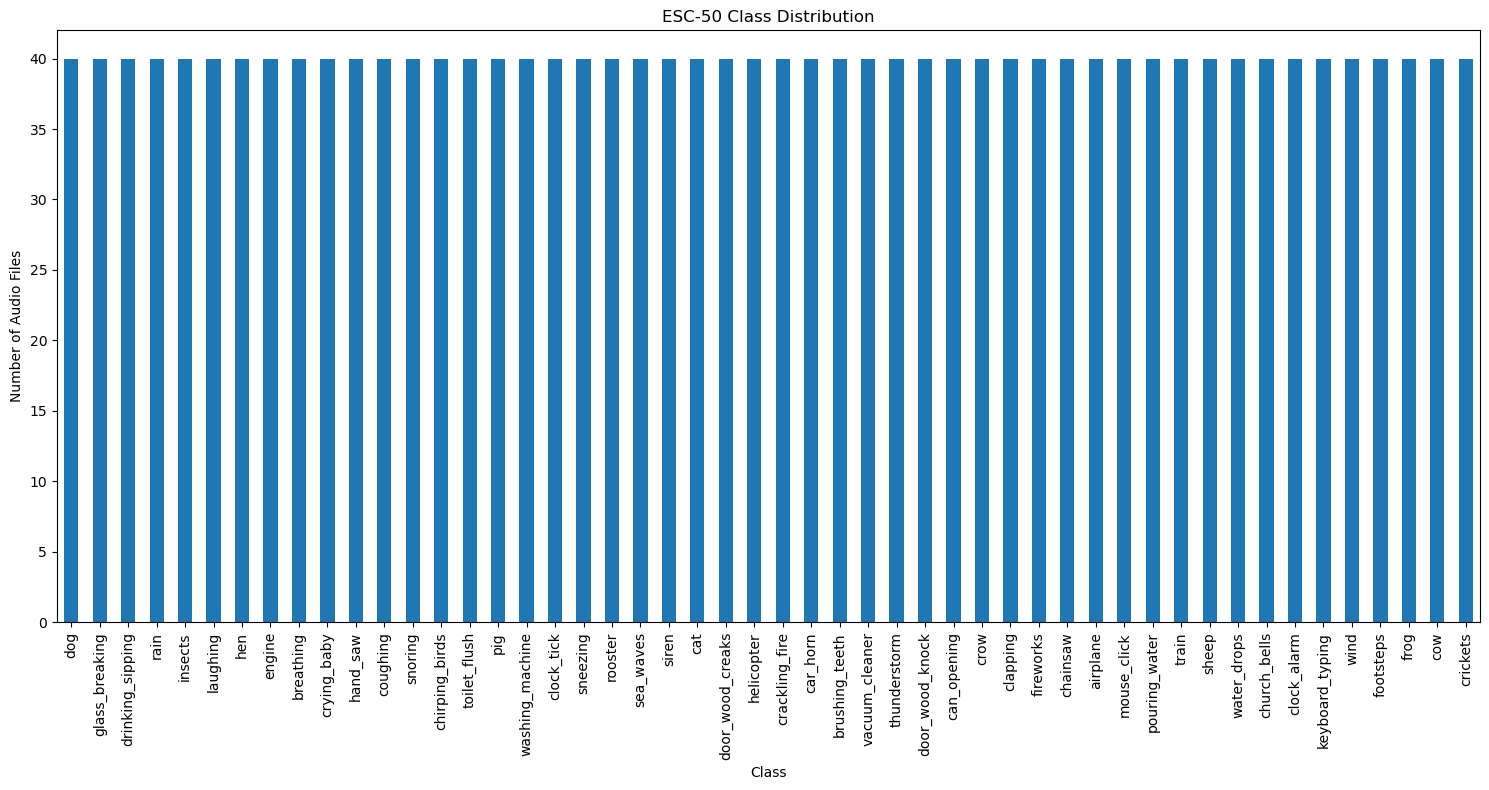

In [5]:
class_counts = df["category"].value_counts()

plt.figure(figsize=(15, 8))

class_counts.plot(
    kind="bar"
)

plt.title(
    "ESC-50 Class Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Audio Files")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

In [6]:
classes = sorted(
    df["category"].unique()
)

class_to_id = {
    name: i
    for i, name in enumerate(classes)
}

id_to_class = {
    i: name
    for i, name in enumerate(classes)
}

df["label"] = df["category"].map(
    class_to_id
)

print(class_to_id)

{'airplane': 0, 'breathing': 1, 'brushing_teeth': 2, 'can_opening': 3, 'car_horn': 4, 'cat': 5, 'chainsaw': 6, 'chirping_birds': 7, 'church_bells': 8, 'clapping': 9, 'clock_alarm': 10, 'clock_tick': 11, 'coughing': 12, 'cow': 13, 'crackling_fire': 14, 'crickets': 15, 'crow': 16, 'crying_baby': 17, 'dog': 18, 'door_wood_creaks': 19, 'door_wood_knock': 20, 'drinking_sipping': 21, 'engine': 22, 'fireworks': 23, 'footsteps': 24, 'frog': 25, 'glass_breaking': 26, 'hand_saw': 27, 'helicopter': 28, 'hen': 29, 'insects': 30, 'keyboard_typing': 31, 'laughing': 32, 'mouse_click': 33, 'pig': 34, 'pouring_water': 35, 'rain': 36, 'rooster': 37, 'sea_waves': 38, 'sheep': 39, 'siren': 40, 'sneezing': 41, 'snoring': 42, 'thunderstorm': 43, 'toilet_flush': 44, 'train': 45, 'vacuum_cleaner': 46, 'washing_machine': 47, 'water_drops': 48, 'wind': 49}


In [7]:
sample_file = df.iloc[0]["filename"]

sample_path = os.path.join(
    AUDIO_PATH,
    sample_file
)

print(
    "File:",
    sample_file
)

audio, sr = librosa.load(
    sample_path,
    sr=None
)

print(
    "Sample rate:",
    sr
)

print(
    "Duration:",
    len(audio) / sr,
    "seconds"
)

File: 1-100032-A-0.wav
Sample rate: 44100
Duration: 5.0 seconds


In [8]:
from IPython.display import Audio, display

display(
    Audio(
        sample_path
    )
)

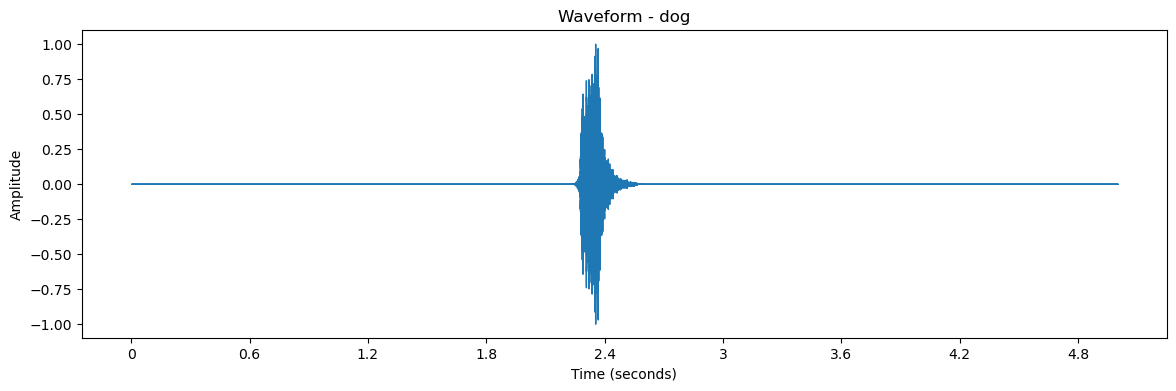

In [9]:
plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title(
    f"Waveform - {df.iloc[0]['category']}"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

# Convert audio to Mel Spectrogram

In [10]:
SAMPLE_RATE = 22050

DURATION = 5

N_MELS = 128

N_FFT = 2048

HOP_LENGTH = 512

In [11]:
def load_audio(file_path):

    audio, sr = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        mono=True
    )

    target_length = (
        SAMPLE_RATE * DURATION
    )

    if len(audio) < target_length:

        audio = np.pad(
            audio,
            (
                0,
                target_length - len(audio)
            )
        )

    else:

        audio = audio[
            :target_length
        ]

    return audio

In [12]:
def audio_to_melspectrogram(
    file_path
):

    audio = load_audio(
        file_path
    )

    mel = librosa.feature.melspectrogram(

        y=audio,

        sr=SAMPLE_RATE,

        n_fft=N_FFT,

        hop_length=HOP_LENGTH,

        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # Normalize
    mel_db = (
        mel_db - mel_db.min()
    ) / (
        mel_db.max()
        - mel_db.min()
        + 1e-8
    )

    return mel_db.astype(
        np.float32
    )

In [13]:
mel = audio_to_melspectrogram(
    sample_path
)

print(
    "Mel shape:",
    mel.shape
)

Mel shape: (128, 216)


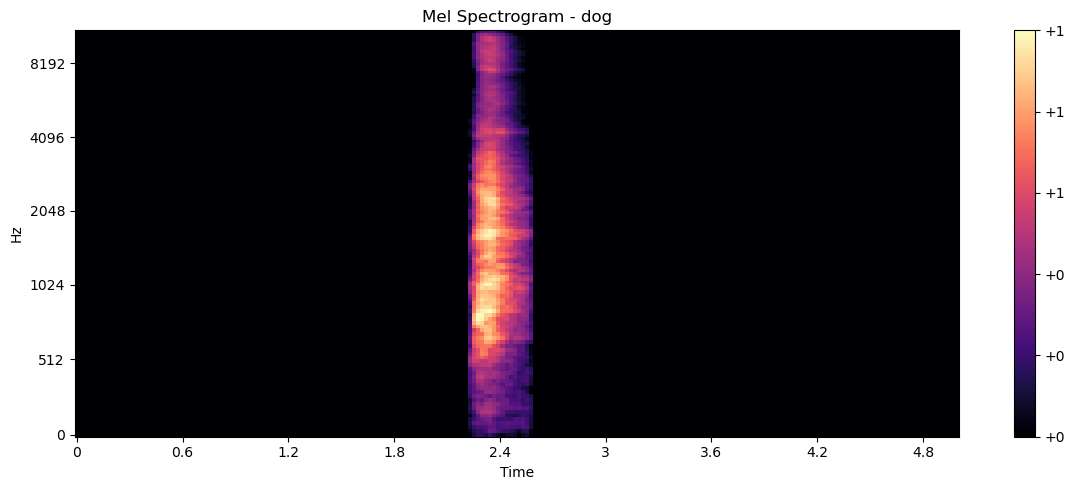

In [14]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(
    format="%+2.0f"
)

plt.title(
    f"Mel Spectrogram - {df.iloc[0]['category']}"
)

plt.tight_layout()

plt.show()

In [15]:
X = []
y = []

for i, row in df.iterrows():

    file_path = os.path.join(
        AUDIO_PATH,
        row["filename"]
    )

    try:

        mel = audio_to_melspectrogram(
            file_path
        )

        X.append(mel)

        y.append(
            row["label"]
        )

    except Exception as e:

        print(
            "Error:",
            file_path,
            e
        )

    if (i + 1) % 100 == 0:

        print(
            f"Processed {i+1}/{len(df)}"
        )

Processed 100/2000
Processed 200/2000
Processed 300/2000
Processed 400/2000
Processed 500/2000
Processed 600/2000
Processed 700/2000
Processed 800/2000
Processed 900/2000
Processed 1000/2000
Processed 1100/2000
Processed 1200/2000
Processed 1300/2000
Processed 1400/2000
Processed 1500/2000
Processed 1600/2000
Processed 1700/2000
Processed 1800/2000
Processed 1900/2000
Processed 2000/2000


In [16]:
X = np.array(X)

y = np.array(y)

print(
    "X:",
    X.shape
)

print(
    "y:",
    y.shape
)

X: (2000, 128, 216)
y: (2000,)


In [17]:
X = X[..., np.newaxis]

print(
    "X shape:",
    X.shape
)

X shape: (2000, 128, 216, 1)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print(
    "Training:",
    X_train.shape
)

print(
    "Testing:",
    X_test.shape
)

Training: (1600, 128, 216, 1)
Testing: (400, 128, 216, 1)


In [19]:
def create_cnn_lstm_model(
    input_shape,
    num_classes
):

    inputs = layers.Input(
        shape=input_shape
    )

    # ==========================
    # CNN BLOCK 1
    # ==========================

    x = layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        activation="relu"
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # ==========================
    # CNN BLOCK 2
    # ==========================

    x = layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # ==========================
    # CNN BLOCK 3
    # ==========================

    x = layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # ==========================
    # CNN → LSTM
    # ==========================

    x = layers.Permute(
        (2, 1, 3)
    )(x)

    x = layers.TimeDistributed(
        layers.Flatten()
    )(x)


    # ==========================
    # LSTM
    # ==========================

    x = layers.LSTM(
        128,
        return_sequences=True
    )(x)

    x = layers.Dropout(
        0.3
    )(x)

    x = layers.LSTM(
        64,
        return_sequences=False
    )(x)


    # ==========================
    # EMBEDDING
    # ==========================

    embedding = layers.Dense(
        128,
        activation="relu",
        name="audio_embedding"
    )(x)


    # ==========================
    # CLASSIFICATION
    # ==========================

    x = layers.Dropout(
        0.4
    )(embedding)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="classifier"
    )(x)


    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )


    return model

In [20]:
model = create_cnn_lstm_model(

    input_shape=X_train.shape[1:],

    num_classes=len(classes)
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 128, 216, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 216, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 216, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 108, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 108, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 108, 64)         │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 54, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 54, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 27, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ permute (Permute)                    │ (None, 27, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 27, 2048)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 27, 128)             │       1,114,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 27, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ audio_embedding (Dense)              │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ classifier (Dense)                   │ (None, 50)                  │           6,450 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,272,370 (4.85 MB)

 Trainable params: 1,271,922 (4.85 MB)

 Non-trainable params: 448 (1.75 KB)

In [21]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(

    "cnn_lstm_best.keras",

    monitor="val_accuracy",

    save_best_only=True,

    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=7,

    restore_best_weights=True,

    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1
)

In [22]:
history = model.fit(

    X_train,

    y_train,

    validation_split=0.15,

    epochs=100,

    batch_size=32,

    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 657ms/step - accuracy: 0.0456 - loss: 3.8144
Epoch 1: val_accuracy improved from None to 0.04583, saving model to cnn_lstm_best.keras

Epoch 1: finished saving model to cnn_lstm_best.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 38s 705ms/step - accuracy: 0.0456 - loss: 3.8144 - val_accuracy: 0.0458 - val_loss: 3.8921 - learning_rate: 0.0010
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step - accuracy: 0.0897 - loss: 3.5749
Epoch 2: val_accuracy did not improve from 0.04583
43/43 ━━━━━━━━━━━━━━━━━━━━ 29s 684ms/step - accuracy: 0.0897 - loss: 3.5749 - val_accuracy: 0.0208 - val_loss: 4.0153 - learning_rate: 0.0010
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 673ms/step - accuracy: 0.1191 - loss: 3.3331
Epoch 3: val_accuracy did not improve from 0.04583
43/43 ━━━━━━━━━━━━━━━━━━━━ 30s 694ms/step - accuracy: 0.1191 - loss: 3.3331 - val_accuracy: 0.0083 - val_loss: 3.9890 - learning_rate: 0.0010
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 661ms/step - accuracy: 0.

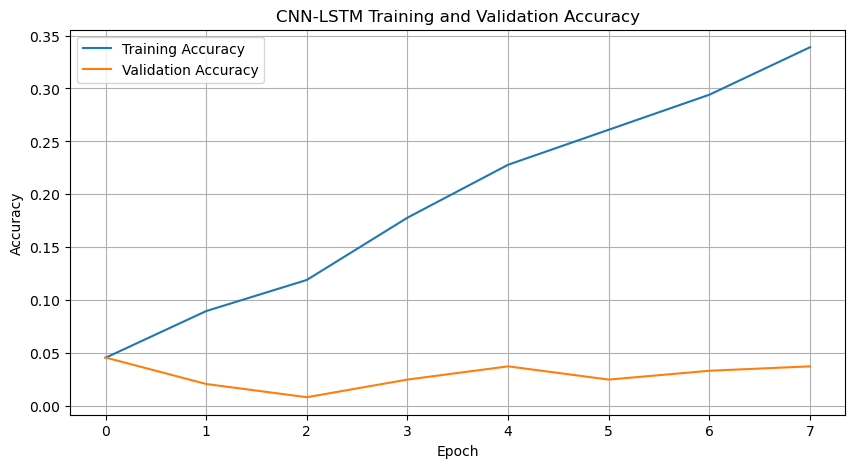

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "CNN-LSTM Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

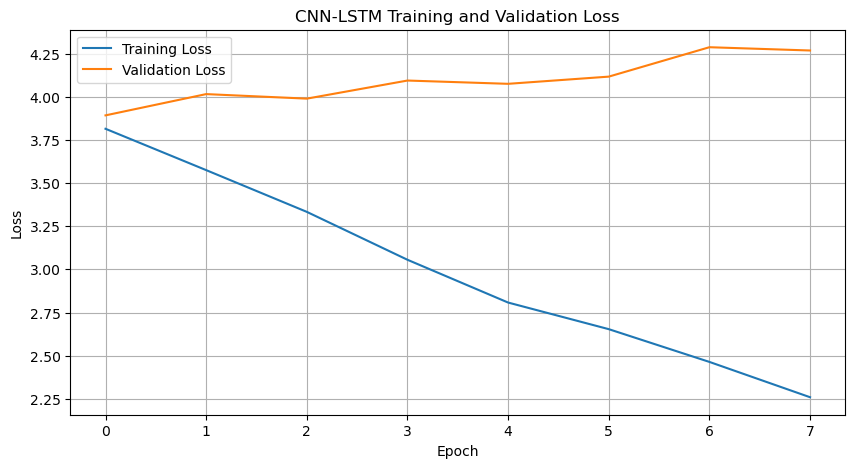

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "CNN-LSTM Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [25]:
test_loss, test_accuracy = model.evaluate(

    X_test,

    y_test,

    verbose=1
)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: {test_accuracy:.4f}"
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.0275 - loss: 3.8977
Test Loss: 3.8977
Test Accuracy: 0.0275


In [26]:
predictions = model.predict(
    X_test
)

predicted_labels = np.argmax(
    predictions,
    axis=1
)

print(
    classification_report(

        y_test,

        predicted_labels,

        target_names=classes
    )
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 158ms/step
                  precision    recall  f1-score   support

        airplane       0.03      0.88      0.05         8
       breathing       0.00      0.00      0.00         8
  brushing_teeth       0.00      0.00      0.00         8
     can_opening       0.00      0.00      0.00         8
        car_horn       0.02      0.12      0.04         8
             cat       0.00      0.00      0.00         8
        chainsaw       0.00      0.00      0.00         8
  chirping_birds       0.00      0.00      0.00         8
    church_bells       0.00      0.00      0.00         8
        clapping       0.00      0.00      0.00         8
     clock_alarm       0.00      0.00      0.00         8
      clock_tick       0.00      0.00      0.00         8
        coughing       0.00      0.00      0.00         8
             cow       0.00      0.00      0.00         8
  crackling_fire       0.00      0.00      0.00         8
        crickets       0.00   

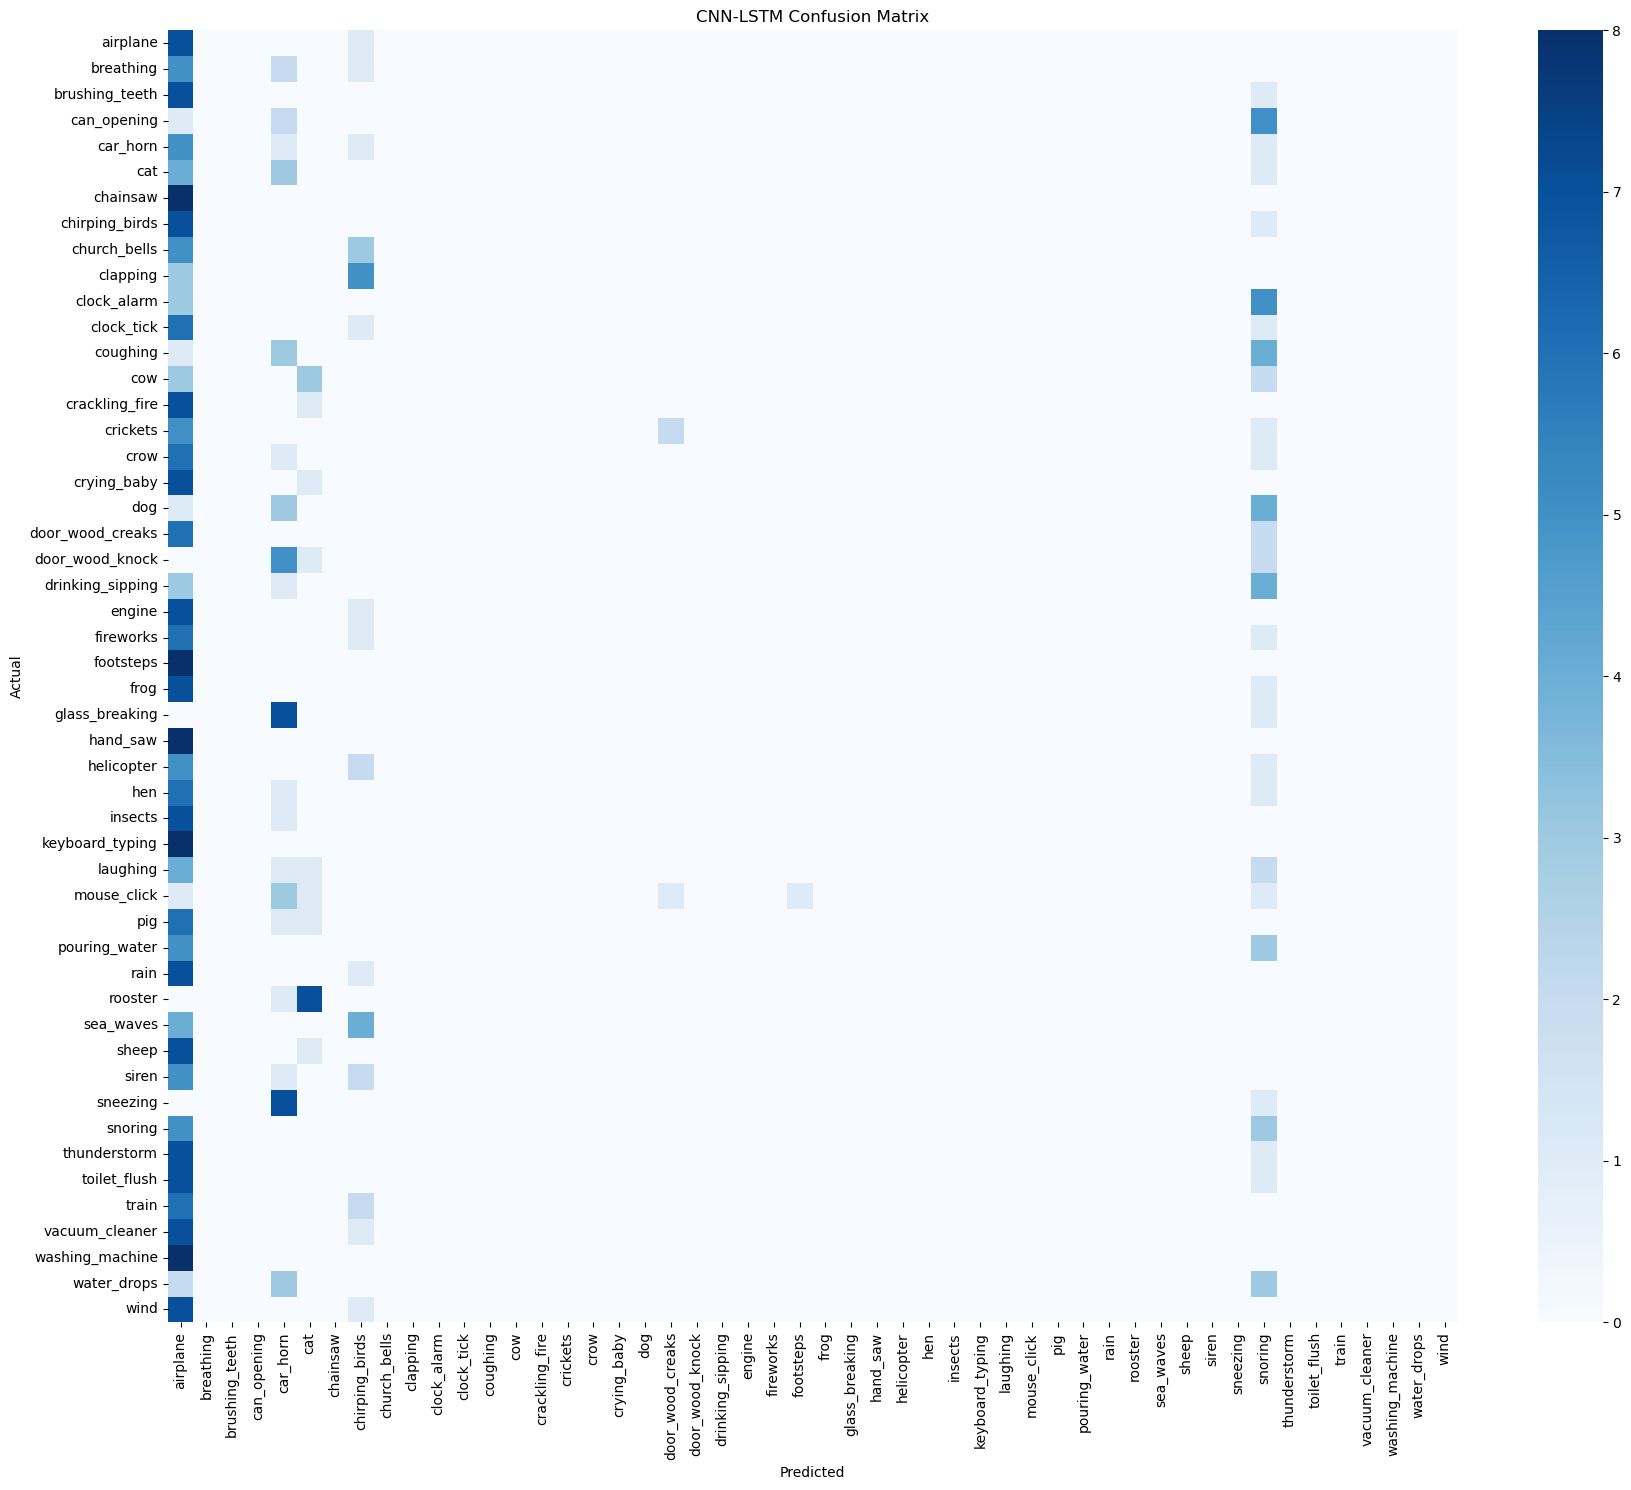

In [27]:
cm = confusion_matrix(

    y_test,

    predicted_labels
)

plt.figure(
    figsize=(18, 15)
)

sns.heatmap(

    cm,

    cmap="Blues",

    xticklabels=classes,

    yticklabels=classes
)

plt.title(
    "CNN-LSTM Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [28]:
model.save(
    "cnn_lstm_audio_classifier.keras"
)

print(
    "Model saved successfully."
)

Model saved successfully.


In [29]:
embedding_model = Model(

    inputs=model.input,

    outputs=model.get_layer(
        "audio_embedding"
    ).output
)

embedding_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 128, 216, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 216, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 216, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 108, 32)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 108, 64)         │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 108, 64)         │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 54, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 54, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 27, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ permute (Permute)                    │ (None, 27, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 27, 2048)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 27, 128)             │       1,114,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 27, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ audio_embedding (Dense)              │ (None, 128)                 │           8,320 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,265,920 (4.83 MB)

 Trainable params: 1,265,472 (4.83 MB)

 Non-trainable params: 448 (1.75 KB)

In [30]:
all_embeddings = embedding_model.predict(

    X,

    batch_size=32,

    verbose=1
)

print(
    "Embedding shape:",
    all_embeddings.shape
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 127ms/step
Embedding shape: (2000, 128)


In [31]:
all_embeddings = all_embeddings.astype(
    "float32"
)

faiss.normalize_L2(
    all_embeddings
)

print(
    all_embeddings.shape
)

(2000, 128)


In [32]:
embedding_dimension = (
    all_embeddings.shape[1]
)

index = faiss.IndexFlatIP(
    embedding_dimension
)

index.add(
    all_embeddings
)

print(
    "Number of vectors:",
    index.ntotal
)

Number of vectors: 2000


In [33]:
metadata = []

for i, row in df.iterrows():

    metadata.append({

        "filename":
            row["filename"],

        "category":
            row["category"],

        "label":
            int(row["label"]),

        "fold":
            int(row["fold"])

    })

metadata[:3]

[{'filename': '1-100032-A-0.wav', 'category': 'dog', 'label': 18, 'fold': 1},
 {'filename': '1-100038-A-14.wav',
  'category': 'chirping_birds',
  'label': 7,
  'fold': 1},
 {'filename': '1-100210-A-36.wav',
  'category': 'vacuum_cleaner',
  'label': 46,
  'fold': 1}]

In [34]:
faiss.write_index(

    index,

    "audio_faiss.index"
)

with open(
    "audio_metadata.pkl",
    "wb"
) as f:

    pickle.dump(
        metadata,
        f
    )

print(
    "FAISS index saved."
)

FAISS index saved.


In [35]:
test_index = 0

query_audio = X_test[
    test_index
]

query_label = y_test[
    test_index
]

print(
    "Actual class:",
    id_to_class[query_label]
)

Actual class: clock_tick


In [36]:
query = query_audio[
    np.newaxis,
    ...
]

In [37]:
query_embedding = embedding_model.predict(
    query
)

query_embedding = query_embedding.astype(
    "float32"
)

faiss.normalize_L2(
    query_embedding
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


In [38]:
k = 5

distances, indices = index.search(

    query_embedding,

    k
)

In [39]:
for rank, (distance, idx) in enumerate(

    zip(
        distances[0],
        indices[0]
    ),

    start=1
):

    print(
        f"{rank}. "
        f"{metadata[idx]['category']} "
        f"| "
        f"{metadata[idx]['filename']} "
        f"| Similarity: {distance:.4f}"
    )

1. clock_tick | 2-88724-A-38.wav | Similarity: 1.0000
2. breathing | 3-166125-B-23.wav | Similarity: 0.9981
3. mouse_click | 1-99958-A-31.wav | Similarity: 0.9979
4. crackling_fire | 3-158476-A-12.wav | Similarity: 0.9975
5. mouse_click | 5-223317-A-31.wav | Similarity: 0.9974


In [40]:
knowledge_data = {

    "dog": {
        "description":
            "A domestic dog can produce barking, whining and growling sounds.",
        "environment":
            "Residential and outdoor environments.",
        "characteristics":
            "Barking is generally characterized by short acoustic events with varying pitch and intensity."
    },

    "cat": {
        "description":
            "Domestic cats produce meowing, purring, hissing and other vocalizations.",
        "environment":
            "Residential and outdoor environments.",
        "characteristics":
            "Cat vocalizations can contain distinct tonal and harmonic patterns."
    },

    "rain": {
        "description":
            "Rain produces broadband environmental noise caused by water droplets.",
        "environment":
            "Outdoor environments.",
        "characteristics":
            "Rain typically produces continuous broadband acoustic energy."
    },

    "thunderstorm": {
        "description":
            "Thunder is a natural acoustic event associated with thunderstorms.",
        "environment":
            "Outdoor environments.",
        "characteristics":
            "Thunder commonly contains strong low-frequency energy and a long temporal duration."
    },

    "car_horn": {
        "description":
            "A car horn is an alert signal produced by a motor vehicle.",
        "environment":
            "Roads and urban environments.",
        "characteristics":
            "Car horns generally contain strong tonal acoustic components."
    }

}

In [41]:
def classify_audio(
    audio_file
):

    mel = audio_to_melspectrogram(
        audio_file
    )

    x = mel[
        np.newaxis,
        ...,
        np.newaxis
    ]

    probabilities = model.predict(
        x,
        verbose=0
    )[0]

    predicted_id = np.argmax(
        probabilities
    )

    confidence = probabilities[
        predicted_id
    ]

    predicted_class = id_to_class[
        predicted_id
    ]

    return (
        predicted_class,
        float(confidence),
        probabilities
    )

In [42]:
def analyze_audio(
    audio_file,
    k=5
):

    # --------------------------------
    # Preprocess
    # --------------------------------

    mel = audio_to_melspectrogram(
        audio_file
    )

    x = mel[
        np.newaxis,
        ...,
        np.newaxis
    ]


    # --------------------------------
    # Classification
    # --------------------------------

    probabilities = model.predict(

        x,

        verbose=0
    )[0]


    predicted_id = np.argmax(
        probabilities
    )


    predicted_class = id_to_class[
        predicted_id
    ]


    confidence = probabilities[
        predicted_id
    ]


    # --------------------------------
    # Embedding
    # --------------------------------

    embedding = embedding_model.predict(

        x,

        verbose=0
    )


    embedding = embedding.astype(
        "float32"
    )


    faiss.normalize_L2(
        embedding
    )


    # --------------------------------
    # FAISS Retrieval
    # --------------------------------

    distances, indices = index.search(

        embedding,

        k
    )


    retrieved = []


    for distance, idx in zip(

        distances[0],

        indices[0]
    ):

        retrieved.append({

            "filename":
                metadata[idx]["filename"],

            "category":
                metadata[idx]["category"],

            "similarity":
                float(distance)

        })


    # --------------------------------
    # Knowledge retrieval
    # --------------------------------

    knowledge = knowledge_data.get(
        predicted_class
    )


    return {

        "prediction":
            predicted_class,

        "confidence":
            float(confidence),

        "retrieved":
            retrieved,

        "knowledge":
            knowledge

    }

In [43]:
test_file = sample_path

result = analyze_audio(
    test_file
)

print(
    "Prediction:",
    result["prediction"]
)

print(
    "Confidence:",
    f"{result['confidence']:.2%}"
)

Prediction: car_horn
Confidence: 2.93%


In [44]:
print(
    "\nSimilar Audio:"
)

for item in result["retrieved"]:

    print(
        f"{item['category']:20s}"
        f" | {item['filename']:30s}"
        f" | {item['similarity']:.3f}"
    )


Similar Audio:
dog                  | 1-100032-A-0.wav               | 1.000
can_opening          | 3-148932-A-34.wav              | 0.999
can_opening          | 1-43764-A-34.wav               | 0.999
glass_breaking       | 5-221528-A-39.wav              | 0.999
water_drops          | 3-164594-A-15.wav              | 0.999


In [45]:
knowledge = result["knowledge"]

if knowledge:

    print(
        "\nKnowledge Retrieved:"
    )

    print(
        "\nDescription:",
        knowledge["description"]
    )

    print(
        "\nEnvironment:",
        knowledge["environment"]
    )

    print(
        "\nCharacteristics:",
        knowledge["characteristics"]
    )

else:

    print(
        "No knowledge available "
        "for this class."
    )


Knowledge Retrieved:

Description: A car horn is an alert signal produced by a motor vehicle.

Environment: Roads and urban environments.

Characteristics: Car horns generally contain strong tonal acoustic components.


In [46]:
def generate_rag_explanation(
    result
):

    prediction = result[
        "prediction"
    ]

    confidence = result[
        "confidence"
    ]

    retrieved = result[
        "retrieved"
    ]

    knowledge = result[
        "knowledge"
    ]


    explanation = []

    explanation.append(
        f"The CNN-LSTM model classified "
        f"the audio as '{prediction}' "
        f"with {confidence:.2%} confidence."
    )


    explanation.append(
        f"FAISS retrieved "
        f"{len(retrieved)} acoustically "
        f"similar audio samples."
    )


    if knowledge:

        explanation.append(
            f"According to the retrieved "
            f"knowledge, {knowledge['description']}"
        )

        explanation.append(
            f"The expected environment is "
            f"{knowledge['environment']}"
        )

        explanation.append(
            f"Relevant acoustic characteristics "
            f"include {knowledge['characteristics']}"
        )


    return " ".join(
        explanation
    )

In [47]:
print(
    generate_rag_explanation(
        result
    )
)

The CNN-LSTM model classified the audio as 'car_horn' with 2.93% confidence. FAISS retrieved 5 acoustically similar audio samples. According to the retrieved knowledge, A car horn is an alert signal produced by a motor vehicle. The expected environment is Roads and urban environments. Relevant acoustic characteristics include Car horns generally contain strong tonal acoustic components.
